In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import json
import os
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

In [85]:
reddit_datasets = {
    'addiction': pd.read_csv('addiction_2019_features_tfidf_256.csv'),
    'adhd': pd.read_csv('adhd_2019_features_tfidf_256.csv'),
    'alcoholism': pd.read_csv('alcoholism_2019_features_tfidf_256.csv'),
    'anxiety': pd.read_csv('anxiety_2019_features_tfidf_256.csv'),
    'jokes': pd.read_csv('jokes_2019_features_tfidf_256.csv'),
    'mentalhealth': pd.read_csv('mentalhealth_2019_features_tfidf_256.csv'),
    'conspiracy': pd.read_csv('conspiracy_2019_features_tfidf_256.csv'),
    'fitness': pd.read_csv('fitness_2019_features_tfidf_256.csv'),
    'meditation': pd.read_csv('meditation_2019_features_tfidf_256.csv'),
    'relationship': pd.read_csv('relationships_2019_features_tfidf_256.csv'),
    'teaching': pd.read_csv('teaching_2019_features_tfidf_256.csv'),
    'suicidewatch': pd.read_csv('suicidewatch_2019_features_tfidf_256.csv'),
}

for name, df in reddit_datasets.items():
    df['subreddit_name'] = name

combined_df = pd.concat(reddit_datasets.values(), ignore_index=True)


In [97]:
depressive_subs = ['suicidewatch', 'mentalhealth', 'anxiety', 'addiction', 'alcoholism']

# Add a binary label: 1 = depression-related, 0 = non-depression
combined_df['label'] = combined_df['subreddit_name'].apply(
    lambda x: 1 if x in depressive_subs else 0
)


tfidf_cols = [c for c in combined_df.columns if c.startswith('tfidf_')]
X = combined_df[tfidf_cols]
y = combined_df['label']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
svm = LinearSVC(random_state=42)
svm.fit(X_train, y_train)

y_pred = svm.predict(X_test)

print("✅ Reddit Accuracy:", accuracy_score(y_test, y_pred))
print("\n📊 Reddit Classification Report:\n", classification_report(y_test, y_pred))

✅ Reddit Accuracy: 0.8865362208204428

📊 Reddit Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.94      0.92     16982
           1       0.86      0.77      0.81      7907

    accuracy                           0.89     24889
   macro avg       0.88      0.86      0.87     24889
weighted avg       0.89      0.89      0.88     24889



In [88]:
import joblib

joblib.dump(svm, "svm_reddit_tfidf.pkl")
joblib.dump(tfidf_cols, "tfidf_feature_names.pkl")  # for reference later


['tfidf_feature_names.pkl']

Twitter Accuracy: 0.18277964414582556

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       1.00      0.18      0.31     16074

    accuracy                           0.18     16074
   macro avg       0.50      0.09      0.15     16074
weighted avg       1.00      0.18      0.31     16074



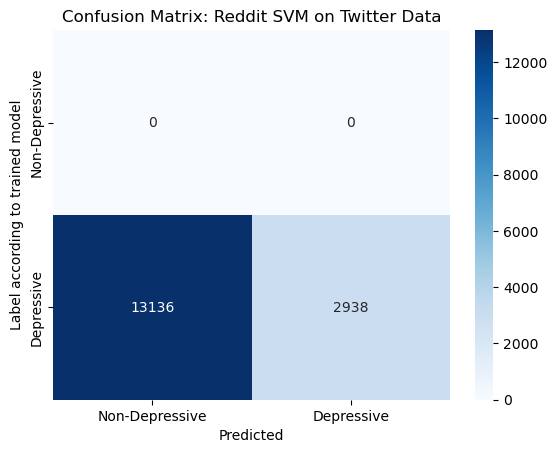

In [96]:

# Load Reddit SVM and TF-IDF vectorizer
svm = joblib.load("svm_reddit.pkl")
vectorizer = joblib.load("tfidf_reddit.pkl")

# Load Twitter datasets
twitter_datasets = {
    'clean_d_tweets': pd.read_csv('clean_d_tweets.csv'),
    'clean_non_d_tweets': pd.read_csv('clean_non_d_tweets.csv'),
    'd_tweets': pd.read_csv('d_tweets.csv'),
    'non_d_tweets': pd.read_csv('non_d_tweets.csv')
}

for name, df in twitter_datasets.items():
    df['twitter_name'] = name

combined_df1 = pd.concat(twitter_datasets.values(), ignore_index=True)

# Create true labels (1 = Depressive, 0 = Non-Depressive)
combined_df1['label'] = combined_df1['twitter_name'].apply(
    lambda x: 1 if 'd_tweets' in x or 'clean_d_tweets' in x else 0
)

# Transform tweets using Reddit TF-IDF vectorizer
X_twitter = vectorizer.transform(combined_df1['tweet'].astype(str))
y_twitter = combined_df1['label']

# Predict using Reddit-trained SVM
twitter_preds = svm.predict(X_twitter)

# Map Reddit subreddit predictions to Depressive / Non-Depressive
depressive_subs = ["suicidewatch", "anxiety", "depression", "mentalhealth", "addiction", "alcoholism"]
predicted_depression = [1 if p in depressive_subs else 0 for p in twitter_preds]

# Evaluate performance
print("Twitter Accuracy:", accuracy_score(y_twitter, predicted_depression))
print("\nClassification Report:\n", classification_report(
    y_twitter, predicted_depression, zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_twitter, predicted_depression)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Non-Depressive","Depressive"],
            yticklabels=["Non-Depressive","Depressive"])
plt.xlabel("Predicted")
plt.ylabel("Label according to trained model")
plt.title("Confusion Matrix: Reddit SVM on Twitter Data")
plt.show()
